# 构建量子线路的三种方法

## 方法1：使用OriginIR字符串

In [1]:
# 导入必要的包 
from pyqpanda3.core import draw_qprog # 打印量子线路，可以用来检查量子线路是否正确
from pyqpanda3.intermediate_compiler import convert_originir_string_to_qprog

**注意**： 从云平台中复制过来的OriginIR需要加上QINIT和CREG，表示量子线路中用到了多少个量子比特和经典比特

一般情况下，量子比特和经典比特数相同，但也有例外。

In [2]:
# Bell态量子线路对应的OriginIR字符串
bell_state_originir = '''QINIT 2
CREG 2
H q[0]
CNOT q[0],q[1]
MEASURE q[0],c[0]
MEASURE q[0],c[0]'''

In [3]:
bell_state_prog = convert_originir_string_to_qprog(bell_state_originir)
print(draw_qprog(bell_state_prog))


          ┌─┐         ┌─┐  ┌─┐ 
q_0:  |0>─┤H├ ───*── ─┤M├ ─┤M├ 
          └─┘ ┌──┴─┐  └╥┘  └╥┘ 
q_1:  |0>──── ┤CNOT├ ──╫─ ──╫─ 
              └────┘   ║    ║  
 c :   / ══════════════╩════╩═
                        0    0




## 方法2：使用OpenQASM字符串

In [4]:
from pyqpanda3.core import draw_qprog
from pyqpanda3.intermediate_compiler import convert_qasm_string_to_qprog

In [5]:
bell_state_openqasm = '''OPENQASM 2.0;
include “qelib1.inc”;

qreg q[2];
creg c[2];
cx q[0], q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];'''

In [6]:
bell_state_prog = convert_originir_string_to_qprog(bell_state_originir)
print(draw_qprog(bell_state_prog))


          ┌─┐         ┌─┐  ┌─┐ 
q_0:  |0>─┤H├ ───*── ─┤M├ ─┤M├ 
          └─┘ ┌──┴─┐  └╥┘  └╥┘ 
q_1:  |0>──── ┤CNOT├ ──╫─ ──╫─ 
              └────┘   ║    ║  
 c :   / ══════════════╩════╩═
                        0    0




## 方法3：实例化QProg对象

**建议**：不要使用`from pyqpanda3.core import *`这种用法，用到什么import什么

In [7]:
from pyqpanda3.core import H, CNOT, measure, QProg, draw_qprog

In [8]:
# 使用QProg(2)构造一个2比特量子线路
bell_state_prog = QProg(2)

# 使用 << 运算符向量子线路中追加量子操作
bell_state_prog << H(0) << CNOT(0, 2)

# 使用for 循环可以批量添加量子门
for i in range(2):
    bell_state_prog << measure(i, i)

In [9]:
print(draw_qprog(bell_state_prog))


          ┌─┐          ┌─┐ 
q_0:  |0>─┤H├─ ───*── ─┤M├ 
          └┬┴┐    │    └╥┘ 
q_1:  |0>──┤M├ ───┼── ──╫─ 
           └╥┘ ┌──┴─┐   ║  
q_2:  |0>───╫─ ┤CNOT├ ──╫─ 
            ║  └────┘   ║  
 c :   / ═══╩═══════════╩═
             1           0




**提示**：

```python
for i in range(2):
    bell_state_prog << measure(i, i)
```
也可以写成：
```python
bell_state_prog << measure(0, 0) << measure(1, 1)
```
或者：
```python
bell_state_prog << measure([0, 1], [0, 1])
```

# 使用模拟器CPUQVM运行量子线路

**流程**：
1. 构造量子程序
2. 实例化`CPUQVM`对象
3. 调用`CPUQVM`对象的`run()`方法运行量子程序
4. 调用`CPUQVM`对象的`result()`方法获取结果

In [10]:
from pyqpanda3.core import H, CNOT, measure, QProg
from pyqpanda3.core import draw_qprog
from pyqpanda3.core import CPUQVM

In [11]:
prog = QProg(2)
prog << H(0)
prog << CNOT(0, 1) << measure(0, 0) << measure(1, 1)
print(draw_qprog(prog))


          ┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1




In [12]:
qvm = CPUQVM()
qvm.run(prog, shots=1000)

In [13]:
result = qvm.result().get_prob_dict()
print(result)

{'00': 0.506, '11': 0.494}


# 使用量子计算机运行

**流程**：
1. 获取APIKEY
2. 选择可用后端
3. 构造量子线路
4. 提交量子线路，得到计算任务实例
5. 根据任务实例对象获取任务计算结果

In [1]:
import os
from pyqpanda3.core import H, CNOT, measure, QProg, draw_qprog
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

## 第一步：获取APIKEY

**注意**：建议将APIKEY保存的环境变量中，防止泄露带来损失！！！

In [2]:
APIKEY = os.getenv('APIKEY')
service = QCloudService(APIKEY)

**注**：选择可用后端之前，先查看当前有哪些后端，为True表示可用，也可以在云平台中看到

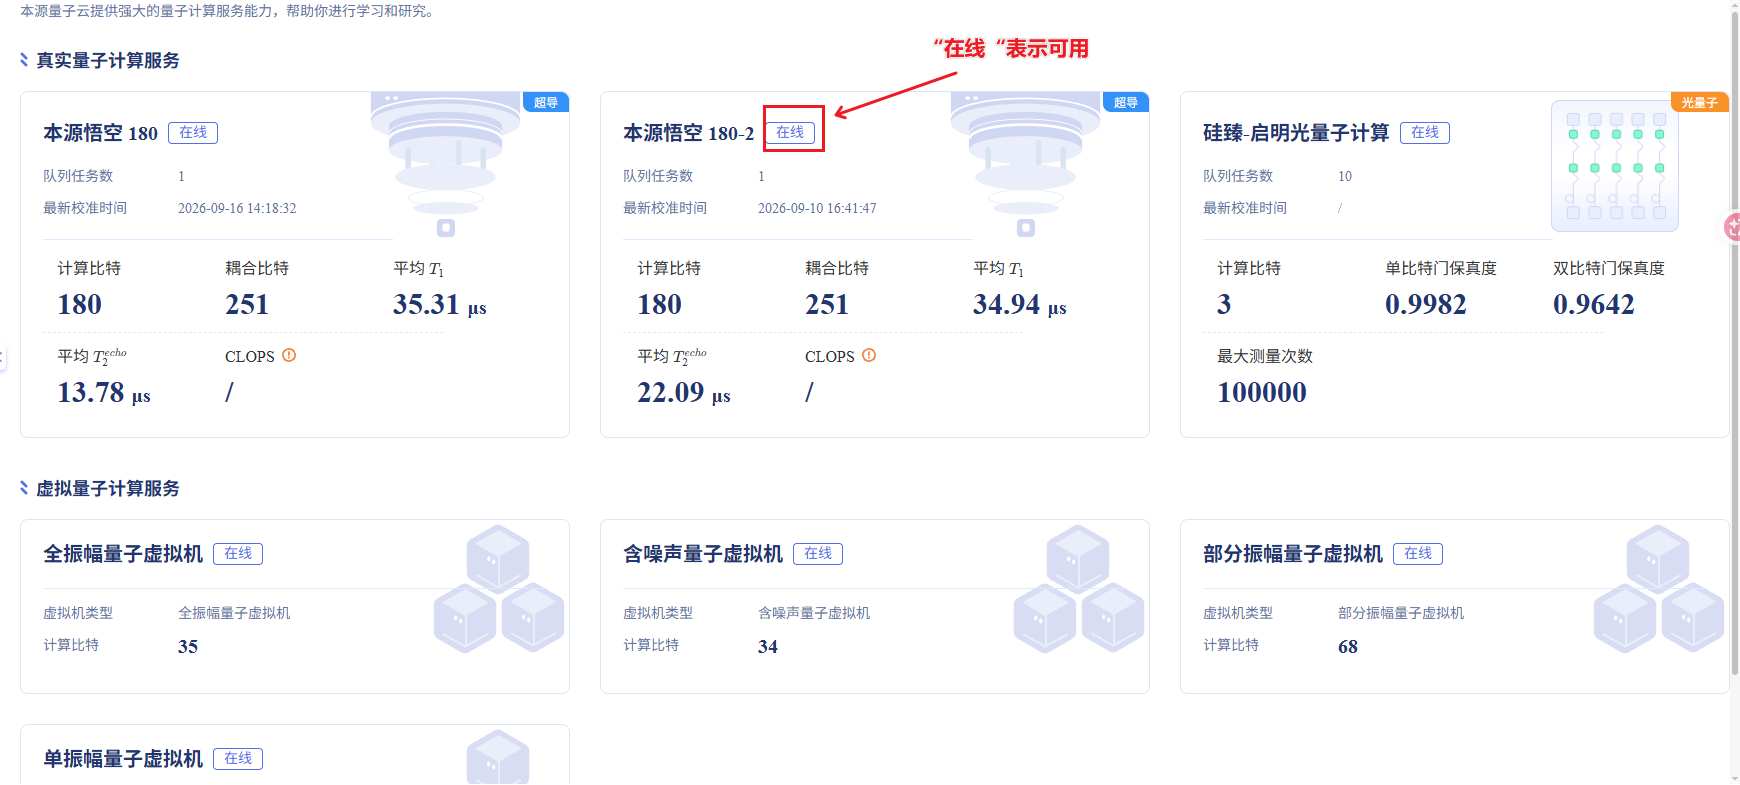

## 第二步：选择可用后端

In [3]:
# 查看可用计算后端
backends = service.backends()
print(backends)

{'HanYuan_01': False, 'PQPUMESH8': True, 'WK_C180': True, 'WK_C180_2': True, 'full_amplitude': True, 'partial_amplitude': True, 'single_amplitude': True}


In [6]:
# WK_C180是真机，选择使用这个后端
backend = service.backend('WK_C180')

## 第三步：构造量子线路

In [5]:
bell_state_prog = QProg(2)
bell_state_prog << H(0) << CNOT(0, 1) << measure(0, 0) << measure(1, 1)
print(draw_qprog(bell_state_prog))


          ┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1




## 第四步：提交量子线路

In [9]:
job = backend.run(bell_state_prog, 1000)
print('当前任务的ID为：', job.job_id())

当前任务的ID为： C823BAE4A27AD21F1DC705D9F11EA7B2


## 第五步：获取计算结果

In [10]:
# 查询任务结果，计算时间与任务队列中任务数量有关
result = job.result().get_probs()
print(result)

{'00': 0.5331608, '01': 8.24e-05, '10': 2.87e-05, '11': 0.4667278}


# 量子隐形传态与动态量子线路

**量子线路**：

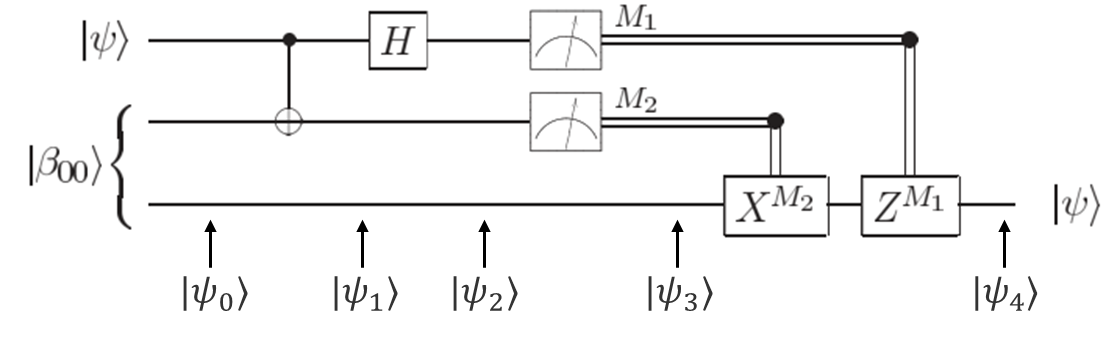

## 第一步：导入必要的包

- RY：用于制备Alice量子比特的初始态
- qif：用于动态量子线路

In [11]:
from numpy import pi
from pyqpanda3.core import H, CNOT, measure, X, Z, QProg
from pyqpanda3.core import RY
from pyqpanda3.core import CPUQVM
from pyqpanda3.core import qif

## 第二步：制备Alice的初态

初始化Alice的未知态: 
$$
|\psi\rangle = \cos\left(\frac{\pi}{3}\right) |0\rangle + \sin\left(\frac{\pi}{3}\right) |1\rangle =  \frac{1}{2} |0\rangle + \frac{\sqrt{3}}{2} |1\rangle
$$

因此，对Alice的量子比特做测量操作，理论上：
$$
\begin{align}
P_0 = \frac{1}{4} \\
P_0 = \frac{3}{4}
\end{align}
$$

In [15]:
prog = QProg(3)

theta = 2 * pi / 3
prog << RY(0, theta)

┌──┐ 
q_0:  |0>─┤RY├ 
          └──┘ 
q_1:  |0>───── 
               
q_2:  |0>───── 
               
 c :   / ═════

## 第三步：准备Alice和Bob的纠缠资源

In [16]:
prog << H(1) << CNOT(1, 2)

┌──┐        
q_0:  |0>─┤RY├ ────── 
          ├─┬┘        
q_1:  |0>─┤H├─ ───*── 
          └─┘  ┌──┴─┐ 
q_2:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

## 第四步：Alice对自己的两个量子比特做联合操作并测量

In [17]:
prog << CNOT(0, 1) << H(0)
prog << measure(0, 0) << measure(1, 1)

┌──┐               ┌─┐   ┌─┐ 
q_0:  |0>─┤RY├ ────── ───*── ┤H├─ ─┤M├ 
          ├─┬┘        ┌──┴─┐ └┬┴┐  └╥┘ 
q_1:  |0>─┤H├─ ───*── ┤CNOT├ ─┤M├ ──╫─ 
          └─┘  ┌──┴─┐ └────┘  └╥┘   ║  
q_2:  |0>───── ┤CNOT├ ────── ──╫─ ──╫─ 
               └────┘          ║    ║  
 c :   / ══════════════════════╩════╩═
                                1    0

## 第五步：Alice将测量结果通过经典信道发送给Bob，Bob根据结果进行校正

**注意**：先作用X门，再作用Z门

In [18]:
x_prog = QProg()
x_prog << X(2)

z_prog = QProg()
z_prog << Z(2)

prog << qif([1]).then(x_prog).qendif()
prog << qif([0]).then(z_prog).qendif()

┌──┐                     ┌─┐     ┌─┐                                  
q_0:  |0>─┤RY├ ────── ───*──────── ┤H├─── ─┤M├─────── ──────────── ─── ──────── 
          ├─┬┘        ┌──┴─┐       └┬┴┐    └╥┘                                  
q_1:  |0>─┤H├─ ───*── ┤CNOT├────── ─┤M├── ──╫──────── ──────────── ─── ──────── 
          └─┘  ┌──┴─┐ ├────┴─────   └╥┼─┐   ║───────┐ ┌──────────  ┌─┐ ───────┐ 
q_2:  |0>───── ┤CNOT├ ┤2 QIF     ─ ──╫┤X├ ──╫ QENDIF├ ┤2 QIF     ─ ┤Z├  QENDIF├ 
               └────┘ └╥─────────    ║└─┘   ║───────┘ └╥─────────  └─┘ ───────┘ 
 c :   / ══════════════╩═════════════╩══════╩══════════╩═══════════════════════
                       1:All 0b1      1      0         0:All 0b1

## 第六步：对Bob的量子比特进行测量操作，统计测量结果

In [19]:
prog << measure(2, 2)

shots = 10000
qvm = CPUQVM()
qvm.run(prog, shots=shots)
result = qvm.result().get_counts()
print(result)

{'011': 668, '110': 1929, '101': 1856, '010': 619, '000': 602, '111': 1885, '100': 1849, '001': 592}


本例通过 `measure(0, 0)`、`measure(1, 1)` 和 `measure(2, 2)`，将量子比特 $q_i$ 的测量结果存入同编号的经典比特 $c_i$。

测量结果字符串从左到右按 $c_2c_1c_0$ 排列，因此在本例中对应 $q_2q_1q_0$：**最左侧是 Bob 的 $q_2$（最高位），最右侧是 $q_0$（最低位）**。例如，`001` 表示 $q_2=0, q_1=0, q_0=1$，而 `100` 表示 $q_2=1, q_1=0, q_0=0$。

因此，`000`、`001`、`010`、`011` 都属于 Bob 测得 $q_2=0$ 的情况；`100`、`101`、`110`、`111` 都属于 $q_2=1$ 的情况。下方代码用 `state.startswith('0')` 判断最左侧一位，并汇总 Bob 测得 0 的次数。

In [20]:
cnt_0, cnt_1 = 0, 0
for state, cnt in result.items():
    if state.startswith('0'):
        cnt_0 += cnt
    else:
        cnt_1 += cnt

p_0 = cnt_0 / shots
p_1 = cnt_1 / shots
print(f'测量得到0的概率为：{p_0}, 得到1的概率为：{p_1}')

测量得到0的概率为：0.2481, 得到1的概率为：0.7519


符合预期：
$$
P_0 = \frac{1}{4}, P_1 = \frac{3}{4}
$$

# 量子态制备与编码

- 基础编码`basic_encode`：编码到计算基态
- 角度编码`angle_encode`：编码到旋转门的角度参数
- 振幅编码`amplitude_encode`：编码到量子态的振幅 
- 稀疏编码`sparse_isometry`：编码稀疏量子态

## 1.基础编码

In [21]:
from pyqpanda3.core import Encode, QProg, measure, CPUQVM, draw_qprog

In [22]:
enc = Encode()
enc.basic_encode([0, 1, 2], "101")

In [23]:
prog = QProg()
prog << enc.get_circuit() << measure([0, 1, 2], [0, 1, 2])

┌─┐      ┌─┐     
q_0:  |0>─┤X├──── ─┤M├──── 
          └─┘ ┌─┐  └╥┘     
q_1:  |0>─────┤M├ ──╫───── 
          ┌─┐ └╥┘   ║  ┌─┐ 
q_2:  |0>─┤X├──╫─ ──╫──┤M├ 
          └─┘  ║    ║  └╥┘ 
 c :   / ══════╩════╩═══╩═
                1    0   2

In [24]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())  # {'101': 1000}

{'101': 1000}


## 2.角度编码

In [25]:
from pyqpanda3.core import Encode, GateType, QProg, measure, CPUQVM, draw_qprog

In [26]:
# 默认使用 RY 门
enc = Encode()
enc.angle_encode([0, 1, 2], [0.5, 1.0, 1.5])

In [27]:
prog = QProg()
prog << enc.get_circuit() << measure([0, 1, 2], [0, 1, 2])

┌──┐  ┌─┐         
q_0:  |0>─┤RY├ ─┤M├──────── 
          ├──┤  └╥┘ ┌─┐     
q_1:  |0>─┤RY├ ──╫──┤M├──── 
          ├──┤   ║  └╥┘ ┌─┐ 
q_2:  |0>─┤RY├ ──╫───╫──┤M├ 
          └──┘   ║   ║  └╥┘ 
 c :   / ════════╩═══╩═══╩═
                  0   1   2

In [28]:
print(draw_qprog(prog, param_show=True))


          ┌──────────────┐  ┌─┐         
q_0:  |0>─┤RY(0.50000000)├ ─┤M├──────── 
          ├──────────────┤  └╥┘ ┌─┐     
q_1:  |0>─┤RY(1.00000000)├ ──╫──┤M├──── 
          ├──────────────┤   ║  └╥┘ ┌─┐ 
q_2:  |0>─┤RY(1.50000000)├ ──╫───╫──┤M├ 
          └──────────────┘   ║   ║  └╥┘ 
 c :   / ════════════════════╩═══╩═══╩═
                              0   1   2




In [29]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())

{'110': 91, '101': 23, '100': 353, '011': 8, '001': 29, '111': 6, '010': 109, '000': 381}


**注**：也可以使用 RX门

In [30]:
# 使用 RX 门
enc2 = Encode()
enc2.angle_encode([0, 1, 2], [0.5, 1.0, 1.5], GateType.RX)
print(draw_qprog(enc2.get_circuit(), param_show=True))


          ┌──────────────┐ 
q_0:  |0>─┤RX(0.50000000)├ 
          ├──────────────┤ 
q_1:  |0>─┤RX(1.00000000)├ 
          ├──────────────┤ 
q_2:  |0>─┤RX(1.50000000)├ 
          └──────────────┘ 
 c :   / ═════════════════
                          




## 3.振幅编码

In [31]:
import numpy as np
from pyqpanda3.core import Encode, QProg, measure, CPUQVM
from pyqpanda3.core import draw_qprog

In [32]:
# 实数值：等叠加态
enc = Encode()
enc.amplitude_encode([0, 1], [0.5, 0.5, 0.5, 0.5])

In [33]:
# 运行
prog = QProg()
prog << enc.get_circuit() << measure([0, 1], [0, 1])

┌──┐     ┌──┐     ┌─┐      
q_0:  |0>───── ┤RY├ ─── ┤RY├ ────┤M├ ──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ └╥┘  ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├──╫─ ─┤M├ 
          └──┘      └─┘      └─┘  ║   └╥┘ 
 c :   / ═════════════════════════╩════╩═
                                   0    1

In [34]:
print(draw_qprog(prog))
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())


               ┌──┐     ┌──┐     ┌─┐      
q_0:  |0>───── ┤RY├ ─── ┤RY├ ────┤M├ ──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ └╥┘  ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├──╫─ ─┤M├ 
          └──┘      └─┘      └─┘  ║   └╥┘ 
 c :   / ═════════════════════════╩════╩═
                                   0    1


{'11': 234, '10': 251, '01': 282, '00': 233}


In [35]:
# 复数值
enc2 = Encode()
data = [0.5+0j, 0.5j, -0.5, 0.5-0.5j]
norm = np.linalg.norm(data)
enc2.amplitude_encode([0, 1], [complex(x/norm) for x in data])

In [36]:
prog2 = QProg()
prog2 << enc2.get_circuit() << measure([0, 1], [0, 1])

┌──┐     ┌──┐       ┌─┐      ┌─┐         ┌─┐     
q_0:  |0>───── ┤RY├ ─── ┤RY├ ─── X ┤X├ ──*─ ┤X├ ──*─ X ─┤M├──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ │ └─┘ ┌─┴┐ └─┘ ┌─┴┐ │  └╥┘ ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├ X ─── ┤U4├ ─── ┤U4├ X ──╫──┤M├ 
          └──┘      └─┘      └─┘       └──┘     └──┘     ║  └╥┘ 
 c :   / ════════════════════════════════════════════════╩═══╩═
                                                          0   1

使用StateVector可以查看量子态矢量

In [38]:
from pyqpanda3.quantum_info import StateVector
init_state = StateVector(2) # |00\rangle
final_state = init_state.evolve(enc2.get_circuit())
print(final_state)

[ 4.47213595e-01+0.00000000e+00j  2.73839349e-17+4.47213595e-01j
 -4.47213595e-01+5.47678698e-17j  4.47213595e-01-4.47213595e-01j]


## 4.稀疏编码

In [39]:
import numpy as np
from pyqpanda3.core import Encode, QProg, measure, CPUQVM
from pyqpanda3.core import draw_qprog

使用字典形式指定量子态每一个分量对应的振幅，需要注意归一化

In [40]:
# 稀疏字典格式
enc = Encode()
data_dict = {"000": 0.40, "001": 0.91, "111": 0.08}
norm = sum(v**2 for v in data_dict.values()) ** 0.5
normalized_data = {k: v/norm for k, v in data_dict.items()}

In [41]:
qubits = [0, 1, 2]
enc.sparse_isometry(qubits, normalized_data)

In [42]:
prog = QProg()
prog << enc.get_circuit()
prog << measure(qubits, qubits)

┌──┐     ┌──┐ ┌─┐     ┌─┐  ┌─┐  ┌─┐     
q_0:  |0>───── ┤RY├ ─── ┤RY├ ┤X├ ─*─ ┤X├─ ┤X├ ─┤M├──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ├─┤  │  └┬┴┐ └┬┘  └╥┘     
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├ ─*─ ─┤M├ ─┼─ ──╫───── 
          └──┘      └─┘      └─┘ ┌┴┐  └╥┘  │    ║  ┌─┐ 
q_2:  |0>───── ──── ─── ──── ─── ┤X├ ──╫─ ─*─ ──╫──┤M├ 
                                 └─┘   ║        ║  └╥┘ 
 c :   / ══════════════════════════════╩════════╩═══╩═
                                        1        0   2

In [43]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())

{'001': 854, '111': 7, '000': 139}


# 量子傅里叶变换

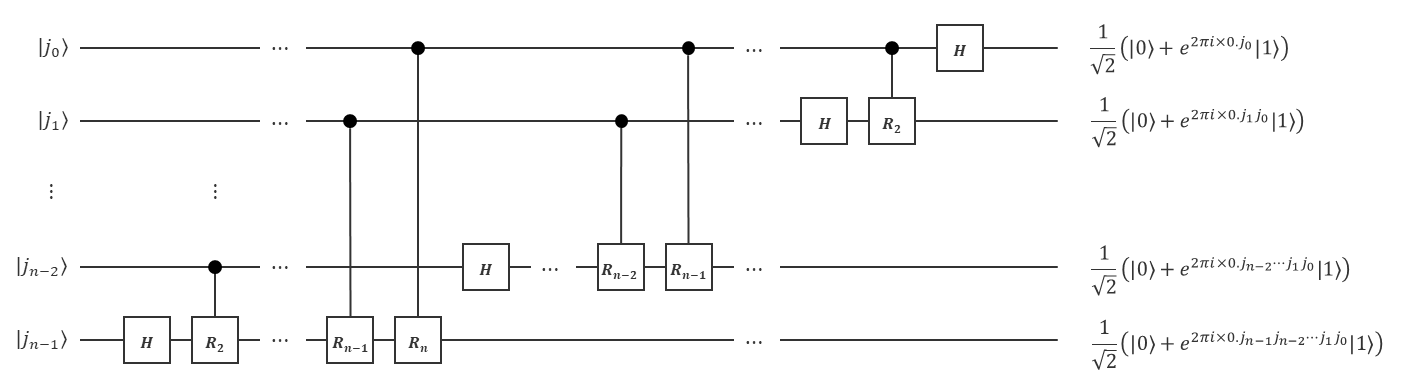

## 例1
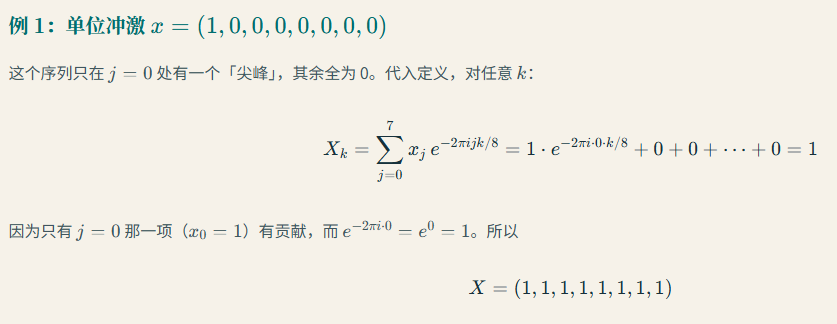

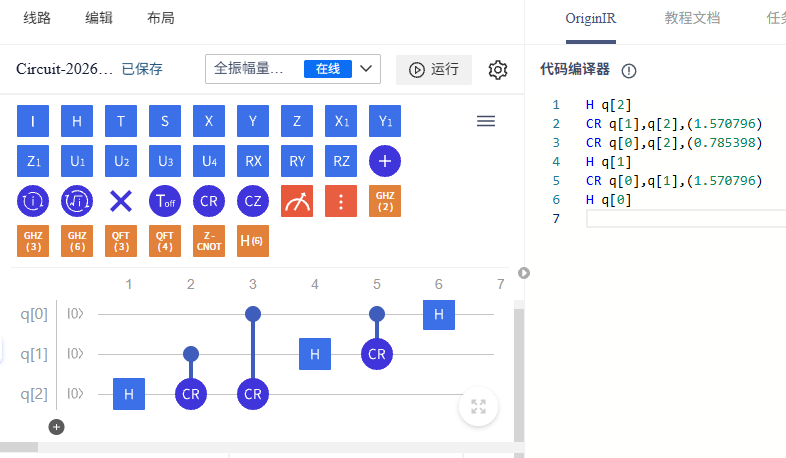

In [95]:
from numpy import pi
from pyqpanda3.core import H, CR, QCircuit, SWAP, draw_qprog
from pyqpanda3.quantum_info import StateVector

In [96]:
qft_q3 = QCircuit(3)
qft_q3 << H(2) << CR(1, 2, pi/2) << CR(0, 2, pi/4)
qft_q3 << H(1) << CR(0, 1, pi/2)
qft_q3 << H(0)

qft_q3 << SWAP(0, 2)

print(draw_qprog(qft_q3, param_show=True))


                                                                 ┌─┐   
q_0:  |0>──── ──────────────── ────────*─────── ────────*─────── ┤H├ X 
                                       │┌─┐     ┌───────┴──────┐ └─┘ │ 
q_1:  |0>──── ────────*─────── ────────┼┤H├──── ┤CP(1.57079633)├ ─── ┼ 
          ┌─┐ ┌───────┴──────┐ ┌───────┴┴─┴───┐ └──────────────┘     │ 
q_2:  |0>─┤H├ ┤CP(1.57079633)├ ┤CP(0.78539816)├ ──────────────── ─── X 
          └─┘ └──────────────┘ └──────────────┘                        
 c :   / ═════════════════════════════════════════════════════════════
                                                                      




In [97]:
init_state = StateVector(3) # |00\rangle
final_state = init_state.evolve(qft_q3)
print(final_state)

[0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j
 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j]
